# Heston Dynamics: Monte Carlo and FFT

This notebook introduces the Heston risk-neutral dynamics and implements the two numerical pricing methods used to create the surrogate training data. Heston has no Black-Scholes elementary pricing formula; its characteristic function supports Fourier pricing, and Carr-Madan FFT is our numerical reference. Monte Carlo estimates are stochastic and are reported with standard errors.

The four-way comparison is in `07_heston_comparison.ipynb`. All prices here are European calls; spot is fixed at 100 and the remaining inputs use the paper's Heston parameter ranges.

In [1]:
from pathlib import Path
import sys
import math
import time

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

ROOT = Path.cwd()
if not (ROOT / "scripts").exists():
    raise FileNotFoundError("Open this notebook with the BTP project root as the working directory.")
sys.path.insert(0, str(ROOT / "scripts"))
from heston_pricing import SPOT, heston_fft_calls, heston_mc_call

SEED = 2027
FFT_N = 4096
FFT_ETA = 0.25
FFT_ALPHA = 1.25
plt.style.use("seaborn-v0_8-whitegrid")
print(f"Spot={SPOT:g}; Carr-Madan FFT N={FFT_N}, eta={FFT_ETA}, alpha={FFT_ALPHA}")

Spot=100; Carr-Madan FFT N=4096, eta=0.25, alpha=1.25


## Risk-neutral Heston model

\[
\frac{dS_t}{S_t}=(r-q)dt+\sqrt{v_t}\,dW^S_t,\qquad
dv_t=\kappa(\theta-v_t)dt+\xi\sqrt{v_t}\,dW^v_t,
\]
\[
\mathrm{corr}(dW^S_t,dW^v_t)=\rho.
\]

Here `v0` is initial variance, `theta` is long-run variance, `kappa` is mean-reversion speed, `xi` is volatility of variance, and `rho` is the Brownian correlation. The paper uses `eta` for long-run variance and `theta` for vol-of-vol; the code uses the common `theta`/`xi` names.

Monte Carlo uses correlated Brownian increments and full-truncation Euler for variance. FFT uses the Heston characteristic function and Carr-Madan damping. Both price the same discounted European call payoff.

## Numerical example and MC convergence

Run the MC at increasing path counts for one at-the-money-forward call. The FFT estimate is the deterministic reference line; the MC error bars show two standard errors from antithetic pair averages.

,paths,mc_price,standard_error,seconds,fft_price
0,10000,7.45716,0.07092,0.17,7.37857
1,30000,7.37945,0.04069,0.49,7.37857
2,80000,7.38028,0.02504,1.26,7.37857


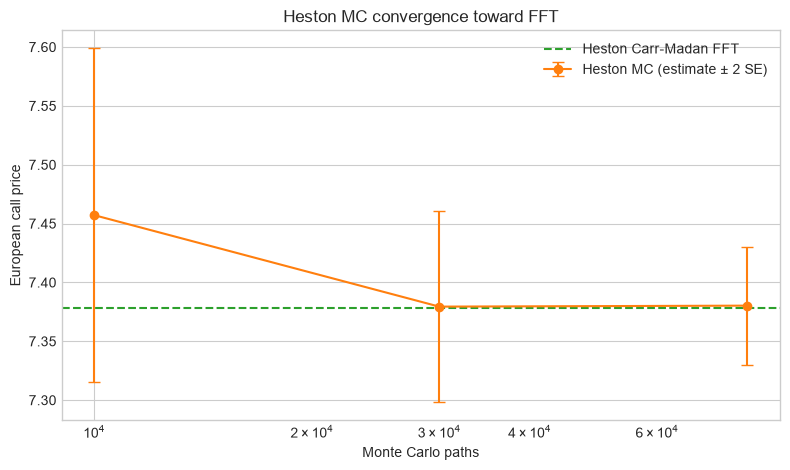

In [2]:
demo = {
    "S": SPOT, "T": 0.95, "r": 0.02, "q": 0.015,
    "kappa": 1.9, "rho": -0.70, "xi": 0.58,
    "theta": 0.045, "v0": 0.050,
}
demo["K"] = demo["S"] * math.exp((demo["r"] - demo["q"]) * demo["T"])
fft_price = heston_fft_calls(demo, [demo["K"]], n=FFT_N, eta=FFT_ETA, alpha=FFT_ALPHA)[0]

mc_rows = []
for paths in (10_000, 30_000, 80_000):
    start = time.perf_counter()
    estimate, standard_error = heston_mc_call(demo, n_paths=paths, n_steps=1000, seed=SEED + paths)
    seconds = time.perf_counter() - start
    mc_rows.append({"paths": paths, "mc_price": estimate, "standard_error": standard_error,
                    "seconds": seconds, "fft_price": fft_price})
mc_convergence = pd.DataFrame(mc_rows)
display(mc_convergence.style.format({"mc_price": "{:.5f}", "standard_error": "{:.5f}",
                                     "seconds": "{:.2f}", "fft_price": "{:.5f}"}))

fig, ax = plt.subplots(figsize=(8, 4.8))
ax.errorbar(mc_convergence["paths"], mc_convergence["mc_price"],
            yerr=2 * mc_convergence["standard_error"], fmt="o-", capsize=4,
            color="tab:orange", label="Heston MC (estimate ± 2 SE)")
ax.axhline(fft_price, color="tab:green", linestyle="--", label="Heston Carr-Madan FFT")
ax.set_xscale("log")
ax.set_xlabel("Monte Carlo paths")
ax.set_ylabel("European call price")
ax.set_title("Heston MC convergence toward FFT")
ax.legend()
fig.tight_layout()
plt.show()

## Pricing functions used downstream

The implementation is shared in `scripts/heston_pricing.py` so data generation and the comparison call identical numerical routines. `heston_fft_calls` prices a strike vector for one market/model context; batching strikes this way makes the 100,000-row training dataset practical. `heston_mc_call` returns both a price and a Monte Carlo standard error.

The FFT grid, damping parameter, MC time steps, path count, and sampling ranges remain visible and configurable in the later notebooks. Check grid stability by increasing `FFT_N`; check the MC estimate by increasing both paths and time steps.